# Notebook 3: Delivery Performance vs Customer Reviews
**Business question:** Do late deliveries lead to worse review scores, and where are deliveries most often late?

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from pathlib import Path

sns.set_theme(style="whitegrid")
IMAGES = Path("../images")

master = pd.read_csv(
    "../data/processed/orders_master.csv",
    parse_dates=["order_purchase_timestamp", "order_delivered_customer_date", "order_estimated_delivery_date"],
)
master = master.dropna(subset=["payment_value"])     # remove the 1 order with no payment

reviewed = master.dropna(subset=["review_score"]).copy()   # only orders that have a review
reviewed["negative_review"] = reviewed["review_score"] <= 2  # 1 or 2 stars counts as negative

print("Orders:", len(master), "| Orders with reviews:", len(reviewed))

Orders: 96469 | Orders with reviews: 95823


In [2]:
kpis = {
    "Delivered orders":            len(master),
    "Avg delivery time (days)":    round(master["delivery_days"].mean(), 1),
    "Median delivery time (days)": master["delivery_days"].median(),
    "Late delivery rate (%)":      round(master["is_late"].mean() * 100, 2),
    "Avg review score":            round(reviewed["review_score"].mean(), 2),
    "Negative review rate (%)":    round(reviewed["negative_review"].mean() * 100, 2),
}
pd.Series(kpis)

Delivered orders               96469.00
Avg delivery time (days)          12.10
Median delivery time (days)       10.00
Late delivery rate (%)             6.77
Avg review score                   4.16
Negative review rate (%)          12.81
dtype: float64

In [3]:
comparison = reviewed.groupby("is_late").agg(
    orders        = ("order_id", "count"),
    avg_review    = ("review_score", "mean"),
    negative_rate = ("negative_review", "mean"),
).round(3)
comparison.index = comparison.index.map({False: "On time / early", True: "Late"})
comparison

,orders,avg_review,negative_rate
is_late,,,
On time / early,89443,4.290,0.093
Late,6380,2.271,0.624


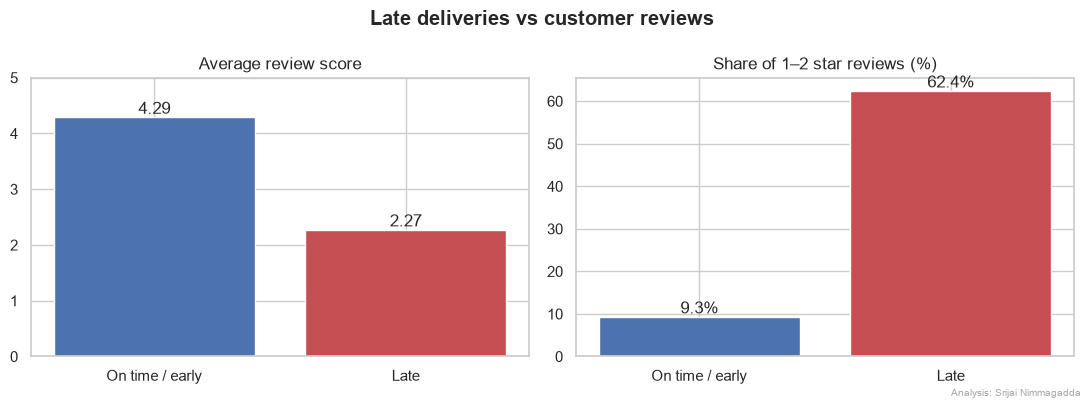

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
colors = ["#4C72B0", "#C44E52"]

bars = axes[0].bar(comparison.index, comparison["avg_review"], color=colors)
axes[0].bar_label(bars, fmt="%.2f")
axes[0].set_ylim(0, 5)
axes[0].set_title("Average review score")

bars = axes[1].bar(comparison.index, comparison["negative_rate"] * 100, color=colors)
axes[1].bar_label(bars, fmt="%.1f%%")
axes[1].set_title("Share of 1–2 star reviews (%)")

fig.suptitle("Late deliveries vs customer reviews", fontweight="bold")
plt.tight_layout()
plt.gcf().text(0.99, 0.01, "Analysis: Srijai Nimmagadda", ha="right", va="bottom", fontsize=7, color="gray", alpha=0.7)
plt.savefig(IMAGES / "01_late_vs_reviews.png", dpi=150, bbox_inches="tight")
plt.show()

In [5]:
bins   = [-np.inf, -10, -1, 0, 3, 7, np.inf]
labels = ["10+ days early", "1–9 days early", "On estimated day",
          "1–3 days late", "4–7 days late", "8+ days late"]
reviewed["delay_bucket"] = pd.cut(reviewed["delay_days"], bins=bins, labels=labels)

bucket = reviewed.groupby("delay_bucket", observed=True).agg(
    orders        = ("order_id", "count"),
    avg_review    = ("review_score", "mean"),
    negative_rate = ("negative_review", "mean"),
).round(3)
bucket

,orders,avg_review,negative_rate
delay_bucket,,,
10+ days early,61523,4.323,0.089
1–9 days early,26640,4.226,0.100
On estimated day,1280,4.034,0.124
1–3 days late,1852,3.291,0.321
4–7 days late,1748,2.103,0.677
8+ days late,2780,1.696,0.793


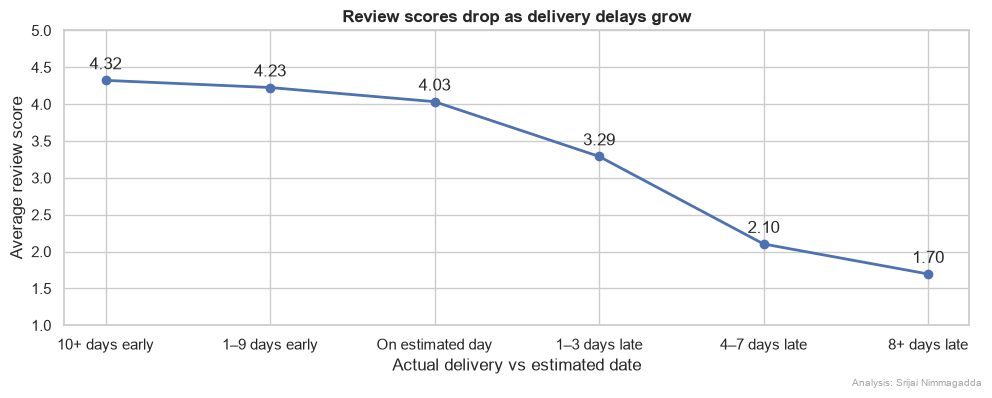

In [13]:
x = bucket.index.astype(str)
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(x, bucket["avg_review"], marker="o", linewidth=2, color="#4C72B0")
for xi, yi in zip(x, bucket["avg_review"]):
    ax.annotate(f"{yi:.2f}", (xi, yi), textcoords="offset points", xytext=(0, 8), ha="center")

ax.set_ylim(1, 5)
ax.set_xlabel("Actual delivery vs estimated date")
ax.set_ylabel("Average review score")
ax.set_title("Review scores drop as delivery delays grow", fontweight="bold")
plt.tight_layout()
plt.gcf().text(0.99, 0.01, "Analysis: Srijai Nimmagadda", ha="right", va="bottom", fontsize=7, color="gray", alpha=0.7)
plt.savefig(IMAGES / "02_review_by_delay.png", dpi=150, bbox_inches="tight")
plt.show()

In [7]:
on_time = reviewed.loc[~reviewed["is_late"], "review_score"]
late    = reviewed.loc[reviewed["is_late"], "review_score"]

# Test 1: are review scores for on-time orders higher than for late orders?
u_stat, p_mw = stats.mannwhitneyu(on_time, late, alternative="greater")
print(f"Mann-Whitney U test: p-value = {p_mw:.2e}")

# Test 2: are negative reviews more common for late orders?
table = pd.crosstab(reviewed["is_late"], reviewed["negative_review"])
chi2, p_chi, dof, _ = stats.chi2_contingency(table)
print(f"Chi-square test:     p-value = {p_chi:.2e}")

Mann-Whitney U test: p-value = 0.00e+00
Chi-square test:     p-value = 0.00e+00


In [10]:
negative = reviewed[reviewed["negative_review"]]
print("Late orders as % of all reviewed orders:   ", round(reviewed["is_late"].mean() * 100, 1), "%")
print("Late orders as % of all negative reviews:  ", round(negative["is_late"].mean() * 100, 1), "%")

Late orders as % of all reviewed orders:    6.7 %
Late orders as % of all negative reviews:   32.5 %


In [8]:
state = master.groupby("customer_state").agg(
    orders            = ("order_id", "count"),
    late_rate         = ("is_late", "mean"),
    avg_delivery_days = ("delivery_days", "mean"),
)
state = state[state["orders"] >= 500].sort_values("late_rate", ascending=False)   # states with enough orders to compare
state["late_rate"] = (state["late_rate"] * 100).round(1)
state["avg_delivery_days"] = state["avg_delivery_days"].round(1)
state

,orders,late_rate,avg_delivery_days
customer_state,,,
MA,717,17.4,21.1
CE,1279,13.8,20.8
BA,3256,12.2,18.9
RJ,12350,12.1,14.8
PA,946,11.2,23.3
ES,1995,10.7,15.3
PB,517,10.4,20.0
MS,701,9.7,15.2
PE,1593,9.6,18.0


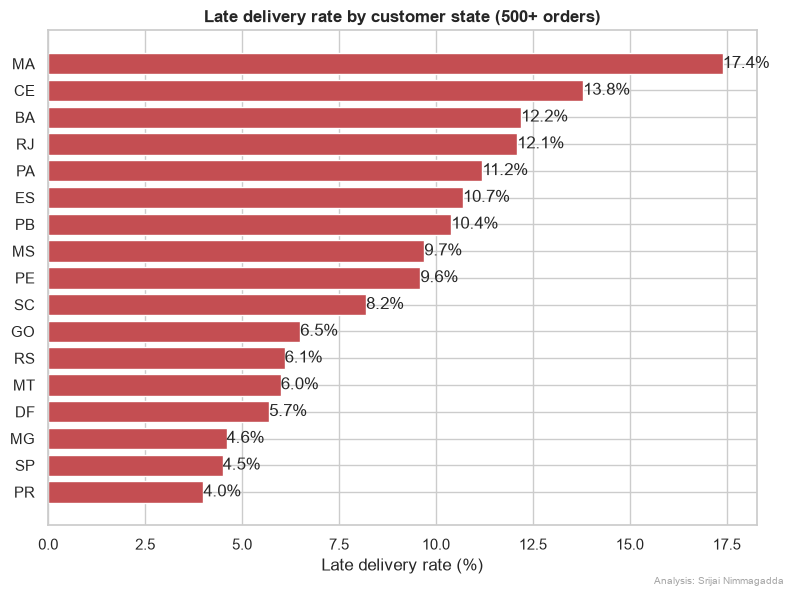

In [11]:
fig, ax = plt.subplots(figsize=(8, 6))
bars = ax.barh(state.index, state["late_rate"], color="#C44E52")
ax.invert_yaxis()                      # highest late rate at the top
ax.bar_label(bars, fmt="%.1f%%")
ax.set_xlabel("Late delivery rate (%)")
ax.set_title("Late delivery rate by customer state (500+ orders)", fontweight="bold")
plt.tight_layout()
plt.gcf().text(0.99, 0.01, "Analysis: Srijai Nimmagadda", ha="right", va="bottom", fontsize=7, color="gray", alpha=0.7)
plt.savefig(IMAGES / "03_late_rate_by_state.png", dpi=150, bbox_inches="tight")
plt.show()

## Key findings
1. **Late delivery rate:** 6.7% of delivered orders arrived after the estimated date.
2. **Impact on reviews:** late orders average 2.27 stars vs 4.29 for on-time orders.
3. **Negative reviews:** 62.4% of late orders get 1–2 stars vs 9.3% of on-time orders (6.7× higher).
4. **The longer the delay, the worse the review:** scores fall from 4.32(10+ days early) to 1.70 (8+ days late).
5. **Statistically significant:** both tests gave p < 0.001.
6. **Where it happens:** the highest late rates are in 17.4 , 13.8 and 12.2.

## Key findings
1. **Late delivery rate:** 6.77% of delivered orders arrived after the estimated date.
2. **Impact on reviews:** late orders average 2.27 stars vs 4.29 for on-time orders.
3. **Negative reviews:** 62.4% of late orders receive 1–2 stars vs 9.3% of on-time orders (6.7× higher).
4. **Delay severity matters:** average scores fall steadily from 4.32 (10+ days early) to 1.70 (8+ days late); even a 1–3 day delay raises the negative review rate from 12.4% to 32.1%.
5. **Statistically significant:** Mann-Whitney U and chi-square tests both gave p < 0.001.
6. **Where it happens:** the highest late rates are in MA (17.4%), CE (13.8%) and BA (12.2%), which are also the states with the longest delivery times (19–21 days). RJ (12.1%) is the largest affected market, with 12,350 orders.
7. **Cautious estimates:** the median order arrives 12 days *before* its estimated date, which suggests Olist's delivery promises are much longer than needed.
8. **Disproportionate impact:** late orders are only 6.7% of reviewed orders but account for 32.5% of all negative reviews.

## Recommendations
- Prioritise logistics improvements for the North-East states and RJ, where late rates are 2–4× higher than in SP.
- Notify customers early when an order is at risk of being late; even small delays sharply increase negative reviews.
- Make delivery estimates more accurate: shorter, realistic promises could improve checkout conversion without hurting reviews.